# Suicidio en Argentina segun SNIC (Ministerio de Seguridad) - provincia y departamento

Companero de `deis_causes_of_death.ipynb` (que usa DEIS/estadisticas vitales). Acá se trabaja la fuente **policial** (SNIC, Sistema Nacional de Información Criminal), que tiene su propia categoría "Suicidios (consumados)" por provincia y por departamento, construida desde denuncias/actuaciones policiales, no desde certificados de defunción.

**Objetivo de este notebook:**
1. Identificar las provincias y departamentos más afectados según SNIC (serie completa y el último año, 2025).
2. Dejar la base armada para comparar, en un paso siguiente, contra las tasas de DEIS (oficial y "corregida") calculadas en el otro notebook.

**Fuentes de este notebook:**
- `data/snic-provincias.csv` — SNIC por provincia, 2000-2025.
- `data/snic-departamentos-anual.csv` — SNIC por departamento, 2000-2025.
- `data/panel_poblacion_depto_2010_2025.csv` — población por departamento, 2010-2025 (denominador). Se extiende linealmente hacia atrás hasta 2000 (sección 4) para poder calcular tasas en toda la ventana de SNIC.


## 1. Configuración y carga

In [1]:
import os
import re
import unicodedata
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ftfy

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['figure.dpi'] = 110

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
SNIC_PROV_PATH = "data/snic-provincias.csv"
SNIC_DEPTO_PATH = "data/snic-departamentos-anual.csv"
POB_DEPTO_PATH = "data/panel_poblacion_depto_2010_2025.csv"

def guardar_fig(nombre, fig=None):
    slug = re.sub(r'[^a-z0-9]+', '_', nombre.lower()).strip('_')
    (fig or plt.gcf()).savefig(f'{FIG_DIR}/{slug}.png', dpi=150, bbox_inches='tight')

snic_prov = pd.read_csv(SNIC_PROV_PATH, sep=None, engine='python', encoding='latin-1')
snic_depto = pd.read_csv(SNIC_DEPTO_PATH, sep=None, engine='python', encoding='latin-1')
pob = pd.read_csv(POB_DEPTO_PATH, sep=None, engine='python', encoding='utf-8-sig')

print('SNIC provincias:', snic_prov.shape, '| años', snic_prov.anio.min(), '-', snic_prov.anio.max())
print('SNIC departamentos:', snic_depto.shape, '| años', snic_depto.anio.min(), '-', snic_depto.anio.max())
print('Población por depto:', pob.shape, '| años', pob.anio.min(), '-', pob.anio.max())


SNIC provincias: (26528, 14) | años 2000 - 2025
SNIC departamentos: (569880, 16) | años 2000 - 2025
Población por depto: (8416, 5) | años 2010 - 2025


## 2. Reparación de encoding y normalización de nombres

`snic-departamentos-anual.csv` tiene un encoding **mixto e inconsistente fila a fila** (parte del archivo quedó con acentos en UTF-8 mal reinterpretados como latin-1, doble mojibake tipo `Ã³` en vez de `ó`). Un `encoding=` único para todo el archivo no alcanza; se usa `ftfy` ("fixes text for you"), que detecta y repara mojibake **por string**, no por archivo entero — ver la comparación antes/después más abajo.


In [2]:
def norm(s):
    """ftfy (repara mojibake) + minuscula + sin acentos + solo alfanumerico/espacios."""
    if pd.isna(s):
        return None
    s = ftfy.fix_text(str(s)).strip().lower()
    s = unicodedata.normalize('NFKD', s)
    s = ''.join(c for c in s if not unicodedata.combining(c))
    s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
    return s if s else None

# Antes / después de ftfy, para un caso con mojibake real
ejemplo = snic_depto.loc[snic_depto['departamento_id'] == 14021, 'departamento_nombre'].iloc[0]
print('crudo (encoding=latin-1):', ejemplo.encode('unicode_escape'))
print('reparado (ftfy):        ', ftfy.fix_text(ejemplo).encode('unicode_escape'))


crudo (encoding=latin-1): b'Col\\xc3\\xb3n'
reparado (ftfy):         b'Col\\xf3n'


## 3. Suicidio por provincia (SNIC): áreas más afectadas

Denominador: población por departamento (sección 1) agregada a nivel provincia — mismo criterio que se va a usar a nivel departamento en la sección 5, para que ambas escalas sean consistentes entre sí.


In [3]:
pob['prov_key'] = pob['provincia'].map(norm)
pob['dep_key'] = pob['departamento'].map(norm)
pob = pob.dropna(subset=['prov_key', 'dep_key'])

pob_prov_year = pob.groupby(['prov_key', 'anio'])['poblacion'].sum()

PROV_ALIAS = {
    'ciudad autonoma de buenos aires': 'caba',
    'tierra del fuego antartida e islas del atlantico sur': 'tierra del fuego',
}

suic_prov = snic_prov[snic_prov['codigo_delito_snic_nombre'] == 'Suicidios (consumados)'].copy()
suic_prov['prov_key'] = suic_prov['provincia_nombre'].map(norm).replace(PROV_ALIAS)

victimas_prov = suic_prov.groupby(['prov_key', 'anio'])['cantidad_victimas'].sum()
prov_year = pd.concat([victimas_prov.rename('victimas'), pob_prov_year.rename('poblacion')], axis=1).dropna()
prov_year['tasa'] = prov_year['victimas'] / prov_year['poblacion'] * 100_000

nombre_prov = (pob[['prov_key', 'provincia']].drop_duplicates('prov_key').rename(columns={'provincia': 'provincia_nombre'}).set_index('prov_key'))

# --- Ranking multi-anio (2015-2025): total victimas / total persona-anios, evita ruido de un anio suelto ---
ventana = prov_year.loc[(slice(None), range(2015, 2026)), :]
rank_prov = ventana.groupby(level=0)[['victimas', 'poblacion']].sum()
rank_prov['tasa'] = rank_prov['victimas'] / rank_prov['poblacion'] * 100_000
rank_prov = rank_prov.join(nombre_prov).sort_values('tasa', ascending=False)

print('Tasa de suicidio SNIC por provincia, promedio anual 2015-2025 (por 100.000 hab.):')
display(rank_prov[['provincia_nombre', 'victimas', 'tasa']].round(2))


Tasa de suicidio SNIC por provincia, promedio anual 2015-2025 (por 100.000 hab.):


,provincia_nombre,victimas,tasa
prov_key,,,
entre rios,Entre Ríos,2450.0,16.08
salta,Salta,2045.0,13.06
san luis,San Luis,674.0,12.06
catamarca,Catamarca,516.0,11.30
santiago del estero,Santiago del Estero,1209.0,11.24
santa cruz,Santa Cruz,429.0,10.66
la rioja,La Rioja,459.0,10.61
santa fe,Santa Fe,4122.0,10.60
formosa,Formosa,690.0,10.38


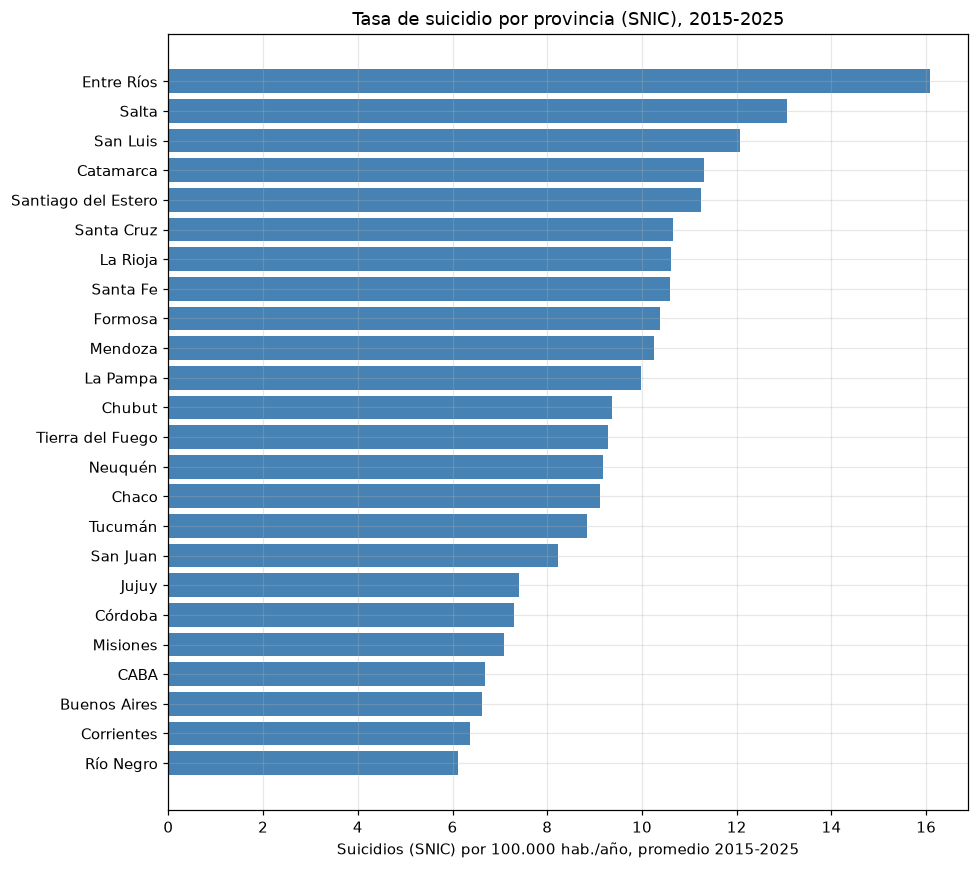


Tasa de suicidio SNIC por provincia, 2025 (por 100.000 hab.):


,provincia_nombre,victimas,tasa
prov_key,,,
entre rios,Entre Ríos,288.0,19.90
san luis,San Luis,96.0,17.80
salta,Salta,243.0,16.09
catamarca,Catamarca,59.0,13.64
tucuman,Tucumán,227.0,12.67
santa fe,Santa Fe,461.0,12.57
santa cruz,Santa Cruz,51.0,12.41
la rioja,La Rioja,50.0,11.94
san juan,San Juan,98.0,11.92


In [4]:
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(rank_prov['provincia_nombre'][::-1], rank_prov['tasa'][::-1], color='steelblue')
ax.set_xlabel('Suicidios (SNIC) por 100.000 hab./año, promedio 2015-2025')
ax.set_title('Tasa de suicidio por provincia (SNIC), 2015-2025')
plt.tight_layout(); guardar_fig('snic_suicidio_por_provincia_2015_2025'); plt.show()

# --- Solo 2025 ---
r2025_prov = prov_year.xs(2025, level='anio').join(nombre_prov).sort_values('tasa', ascending=False)
print('\nTasa de suicidio SNIC por provincia, 2025 (por 100.000 hab.):')
display(r2025_prov[['provincia_nombre', 'victimas', 'tasa']].round(2))


## 4. Departamento: apareo con los denominadores de población

El panel de población no tiene código INDEC, solo nombre de provincia + departamento, así que el cruce con SNIC (que sí tiene `departamento_id` INDEC) es por **nombre normalizado**. Con eso solo, la cobertura es baja: hay convenciones de escritura distintas entre las dos fuentes ("Grl." vs. "General", "1º de Mayo" vs. "1° de Mayo", las comunas de CABA como "Comuna 7" vs. "7", etc.). Se resuelve en tres pasos, y se reporta explícitamente qué queda afuera:

1. Match directo por (provincia, departamento) normalizados.
2. Casos conocidos: alias de provincia (CABA, Tierra del Fuego) y comunas de CABA (`comuna N` → `N`).
3. Match difuso (`difflib`) dentro de la misma provincia para el resto, **revisado a mano** — dos matches difusos salieron mal ("Lezama" → "Lomas de Zamora"; los 4 "distritos" de La Pampa del SNIC, que no son departamentos INDEC reales) y se excluyen explícitamente en vez de aceptarse.

Lo que queda sin resolver es sobre todo la categoría **"Departamento sin determinar"** de SNIC (víctima sin geolocalizar a nivel departamento) — no es un error de cruce, es información que SNIC no tiene a ese nivel de detalle.


In [5]:
suic_dep = snic_depto[snic_depto['codigo_delito_snic_nombre'] == 'Suicidios (consumados)'].copy()
suic_dep['prov_key'] = suic_dep['provincia_nombre'].map(norm).replace(PROV_ALIAS)
suic_dep['dep_key'] = suic_dep['departamento_nombre'].map(norm)
suic_dep = suic_dep.dropna(subset=['prov_key', 'dep_key'])

# CABA: 'comuna 7' -> '7', para calzar con las etiquetas numericas del panel de poblacion
es_caba = suic_dep['prov_key'] == 'caba'
suic_dep.loc[es_caba, 'dep_key'] = suic_dep.loc[es_caba, 'dep_key'].str.replace(r'^comuna\s*', '', regex=True)

# Exclusiones revisadas a mano (ver seccion 4, texto de arriba)
EXCLUIR_DEPKEY = {'departamento sin determinar'}
EXCLUIR_PROV_DEPKEY = {
    ('la pampa', 'centro'), ('la pampa', 'norte'), ('la pampa', 'sur'),
    ('la pampa', 'centro santa rosa'), ('la pampa', 'norte general pico'),
    ('la pampa', 'sur general acha'), ('la pampa', 'oeste'), ('la pampa', 'oeste 25 de mayo'),
    ('tierra del fuego', 'tolhuin'),            # localidad, no es un departamento INDEC separado
    ('san luis', 'juan martin de pueyrredon'),  # no se pudo confirmar a que depto INDEC corresponde
    ('buenos aires', 'lezama'),                 # el match difuso ingenuo lo confundia con Lomas de Zamora
}
suic_dep['key'] = list(zip(suic_dep['prov_key'], suic_dep['dep_key']))
excluido = suic_dep[suic_dep['dep_key'].isin(EXCLUIR_DEPKEY) | suic_dep['key'].isin(EXCLUIR_PROV_DEPKEY)]
suic_dep_ok = suic_dep[~(suic_dep['dep_key'].isin(EXCLUIR_DEPKEY) | suic_dep['key'].isin(EXCLUIR_PROV_DEPKEY))].copy()

print(f"Excluido (sin depto INDEC confiable): {int(excluido['cantidad_victimas'].sum())} víctimas "
      f"de {int(suic_dep['cantidad_victimas'].sum())} (2000-2025) "
      f"({100*excluido['cantidad_victimas'].sum()/suic_dep['cantidad_victimas'].sum():.1f}%)")
print(excluido.groupby('departamento_nombre')['cantidad_victimas'].sum().sort_values(ascending=False).head(8))


Excluido (sin depto INDEC confiable): 7738 víctimas de 81045 (2000-2025) (9.5%)
departamento_nombre
Departamento sin determinar    6851.0
Centro (Santa Rosa)             275.0
Norte (General Pico)            191.0
Juan MartÃ­n de PueyrredÃ³n     139.0
Centro                          105.0
Sur (General Acha)               63.0
Norte                            47.0
Oeste (25 de Mayo)               24.0
Name: cantidad_victimas, dtype: float64


In [6]:
# --- Match directo + match difuso (dentro de la misma provincia) para el resto ---
pob_por_prov = {p: g['dep_key'].tolist() for p, g in pob.groupby('prov_key')}
pob_keys = set(pob['prov_key'] + '|' + pob['dep_key'])

def resolver_depkey(prov_key, dep_key):
    if f'{prov_key}|{dep_key}' in pob_keys:
        return dep_key
    candidatos = pob_por_prov.get(prov_key, [])
    match = difflib.get_close_matches(dep_key, candidatos, n=1, cutoff=0.6)
    return match[0] if match else None

suic_dep_ok['dep_key_resuelto'] = [resolver_depkey(p, d) for p, d in zip(suic_dep_ok['prov_key'], suic_dep_ok['dep_key'])]

sin_resolver = suic_dep_ok[suic_dep_ok['dep_key_resuelto'].isna()]
if len(sin_resolver):
    print('Sin resolver (revisar si conviene agregar a las exclusiones):')
    display(sin_resolver[['provincia_nombre', 'departamento_nombre']].drop_duplicates())

suic_dep_final = suic_dep_ok.dropna(subset=['dep_key_resuelto']).copy()
suic_dep_final['dkey'] = suic_dep_final['prov_key'] + '|' + suic_dep_final['dep_key_resuelto']

cobertura = suic_dep_final['cantidad_victimas'].sum()
total = suic_dep['cantidad_victimas'].sum()
print(f"\nCobertura final: {int(cobertura)}/{int(total)} = {100*cobertura/total:.1f}% de las víctimas "
      "(2000-2025) quedan con departamento INDEC y población asignados.")



Cobertura final: 73307/81045 = 90.5% de las víctimas (2000-2025) quedan con departamento INDEC y población asignados.


### 4b. Forecast lineal de población hacia atrás, hasta 2000

El panel de población arranca en 2010, pero SNIC tiene datos desde 2000. Para poder calcular tasas en toda la ventana, se ajusta una regresión lineal simple (población ~ año) por departamento sobre los puntos reales 2010-2025, y se extrapola 2000-2009. Es una aproximación razonable para una extensión corta (10 años) de una serie que ya es monótona y suave en el tramo observado — no es una proyección demográfica real (no captura migraciones puntuales, cambios de límites departamentales, etc.).


In [7]:
pob['dkey'] = pob['prov_key'] + '|' + pob['dep_key']
pob_base = pob[['dkey', 'provincia', 'departamento', 'anio', 'poblacion']]

extrapolado = []
for dkey, g in pob_base.groupby('dkey'):
    g = g.sort_values('anio')
    pendiente, ordenada = np.polyfit(g['anio'], g['poblacion'], 1)
    for anio in range(2000, 2010):
        extrapolado.append((dkey, g['provincia'].iloc[0], g['departamento'].iloc[0],
                             anio, max(0, pendiente * anio + ordenada)))
extrapolado = pd.DataFrame(extrapolado, columns=['dkey', 'provincia', 'departamento', 'anio', 'poblacion'])

pob_full = pd.concat([pob_base, extrapolado], ignore_index=True)
nombre_dep = pob_full[['dkey', 'provincia', 'departamento']].drop_duplicates('dkey').set_index('dkey')

print(f'Población por departamento: {pob_full.dkey.nunique()} departamentos, '
      f'años {pob_full.anio.min()}-{pob_full.anio.max()} '
      f'({pob_base.anio.min()}-{pob_base.anio.max()} real, {2000}-{2009} extrapolado)')

ej = pob_full[pob_full.dkey == nombre_dep.index[0]].sort_values('anio')
display(ej.head(3))


Población por departamento: 526 departamentos, años 2000-2025 (2010-2025 real, 2000-2009 extrapolado)


,dkey,provincia,departamento,anio,poblacion
8416,buenos aires|25 de mayo,Buenos Aires,25 de Mayo,2000,35280.75
8417,buenos aires|25 de mayo,Buenos Aires,25 de Mayo,2001,35369.80
8418,buenos aires|25 de mayo,Buenos Aires,25 de Mayo,2002,35458.85


## 5. Departamento: áreas más afectadas

**Ojo con el N chico:** la mayoría de los ~500 departamentos de Argentina tienen poblaciones de pocos miles de habitantes, así que un año con 2 o 3 suicidios da tasas absurdamente altas por puro ruido estadístico. Se muestran dos vistas: (a) el ranking **sin filtrar**, para que se vea explícitamente el problema, y (b) el ranking recomendado, con **piso de población** y **acumulado multi-año** (2015-2025, total víctimas / total persona-años) en vez de tasas anuales sueltas.


In [8]:
victimas_dep_anio = suic_dep_final.groupby(['dkey', 'anio'])['cantidad_victimas'].sum().reset_index()
dep_anio = victimas_dep_anio.merge(pob_full[['dkey', 'anio', 'poblacion']], on=['dkey', 'anio'], how='left')
assert dep_anio['poblacion'].notna().all(), 'hay filas sin población asignada'

# --- (a) 2025, SIN piso de poblacion: el problema del N chico, a la vista ---
r2025_dep = dep_anio[dep_anio.anio == 2025].copy()
r2025_dep['tasa'] = r2025_dep['cantidad_victimas'] / r2025_dep['poblacion'] * 100_000
r2025_dep = r2025_dep.join(nombre_dep, on='dkey')

print('Top 10 departamentos por tasa 2025, SIN piso de población (ejemplo del problema de N chico):')
display(r2025_dep.sort_values('tasa', ascending=False)
        [['provincia', 'departamento', 'cantidad_victimas', 'poblacion', 'tasa']].head(10).round(1))


Top 10 departamentos por tasa 2025, SIN piso de población (ejemplo del problema de N chico):


,provincia,departamento,cantidad_victimas,poblacion,tasa
7643,Jujuy,Susques,4.0,4233.0,94.5
11006,San Juan,Ullum,5.0,5885.0,85.0
4159,Catamarca,Paclín,3.0,4302.0,69.7
8094,La Rioja,General Juan F. Quiroga,2.0,3634.0,55.0
12380,Santiago del Estero,Mitre,1.0,2084.0,48.0
11110,San Luis,Belgrano,2.0,4367.0,45.8
10252,Salta,La Caldera,5.0,11782.0,42.4
10356,Salta,Los Andes,3.0,7117.0,42.2
7790,La Pampa,Hucal,3.0,7234.0,41.5
831,Buenos Aires,Coronel Dorrego,6.0,14864.0,40.4


Departamentos más afectados, tasa promedio anual 2015-2025 (población promedio >= 20,000):


,provincia,departamento,victimas,poblacion_prom,tasa
dkey,,,,,
buenos aires|dolores,Buenos Aires,Dolores,64.0,28703.5,20.3
entre rios|nogoya,Entre Ríos,Nogoyá,92.0,41264.7,20.3
entre rios|colon,Entre Ríos,Colón,169.0,77103.3,19.9
buenos aires|la costa,Buenos Aires,La Costa,171.0,78496.2,19.8
entre rios|federal,Entre Ríos,Federal,61.0,28165.6,19.7
santiago del estero|pellegrini,Santiago del Estero,Pellegrini,47.0,22151.2,19.3
entre rios|uruguay,Entre Ríos,Uruguay,236.0,113096.0,19.0
santa fe|san javier,Santa Fe,San Javier,69.0,34057.1,18.4
entre rios|villaguay,Entre Ríos,Villaguay,106.0,52600.9,18.3


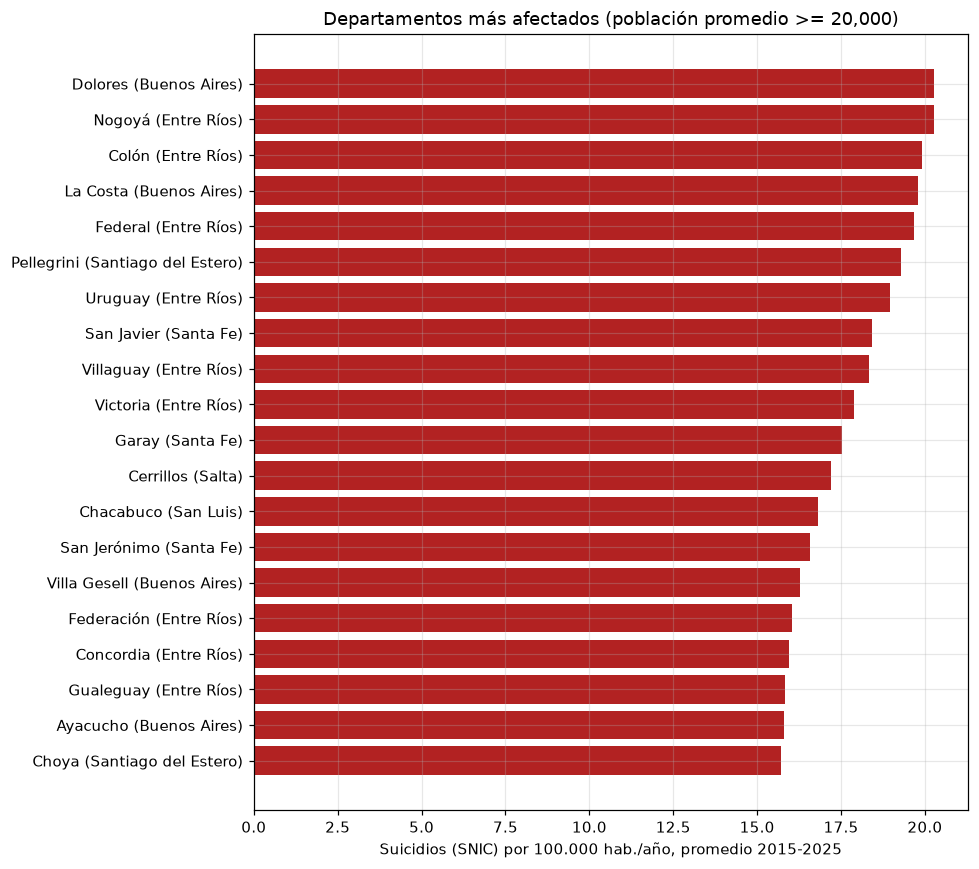

In [9]:
# --- (b) Ranking recomendado: acumulado 2015-2025, piso de poblacion promedio >= 20,000 ---
PISO_POBLACION = 20_000
ANIOS_RANKING = range(2015, 2026)

acumulado = (dep_anio[dep_anio.anio.isin(ANIOS_RANKING)]
             .groupby('dkey')[['cantidad_victimas', 'poblacion']].sum()
             .rename(columns={'cantidad_victimas': 'victimas', 'poblacion': 'persona_anios'}))
acumulado['tasa'] = acumulado['victimas'] / acumulado['persona_anios'] * 100_000
acumulado['poblacion_prom'] = acumulado['persona_anios'] / len(ANIOS_RANKING)
acumulado = acumulado.join(nombre_dep)

rank_dep = acumulado[acumulado['poblacion_prom'] >= PISO_POBLACION].sort_values('tasa', ascending=False)
print(f'Departamentos más afectados, tasa promedio anual {ANIOS_RANKING[0]}-{ANIOS_RANKING[-1]} '
      f'(población promedio >= {PISO_POBLACION:,}):')
display(rank_dep[['provincia', 'departamento', 'victimas', 'poblacion_prom', 'tasa']].head(20).round(1))

fig, ax = plt.subplots(figsize=(9, 8))
top20 = rank_dep.head(20).iloc[::-1]
etiquetas = top20['departamento'] + ' (' + top20['provincia'] + ')'
ax.barh(etiquetas, top20['tasa'], color='firebrick')
ax.set_xlabel(f'Suicidios (SNIC) por 100.000 hab./año, promedio {ANIOS_RANKING[0]}-{ANIOS_RANKING[-1]}')
ax.set_title(f'Departamentos más afectados (población promedio >= {PISO_POBLACION:,})')
plt.tight_layout(); guardar_fig('snic_suicidio_top_departamentos_2015_2025'); plt.show()


In [10]:
# --- 2025 solo, mismo piso de poblacion (para el titular "donde fue mas alta en 2025") ---
r2025_filtrado = r2025_dep[r2025_dep['poblacion'] >= PISO_POBLACION].sort_values('tasa', ascending=False)
print(f'Tasa más alta en 2025 (población >= {PISO_POBLACION:,}):')
display(r2025_filtrado[['provincia', 'departamento', 'cantidad_victimas', 'poblacion', 'tasa']].head(15).round(1))


Tasa más alta en 2025 (población >= 20,000):


,provincia,departamento,cantidad_victimas,poblacion,tasa
1715,Buenos Aires,La Costa,28.0,82379.0,34.0
4289,Catamarca,Valle Viejo,11.0,33525.0,32.8
7071,Entre Ríos,Victoria,13.0,41152.0,31.6
467,Buenos Aires,Bragado,13.0,42338.0,30.7
935,Buenos Aires,Dolores,9.0,29370.0,30.6
415,Buenos Aires,Berisso,30.0,100126.0,30.0
7019,Entre Ríos,Tala,8.0,26739.0,29.9
3431,Buenos Aires,Villa Gesell,12.0,40812.0,29.4
6837,Entre Ríos,Gualeguay,18.0,61320.0,29.4
259,Buenos Aires,Azul,19.0,68487.0,27.7


## 6. Cruce con DEIS

DEIS (estadísticas vitales) todavía no publicó 2025 — el archivo más reciente es `defuncion2024.csv`. Para los **mapas** se usa 2024 (último año en común entre las dos fuentes); para las **líneas de tiempo** se muestra cada serie hasta donde llega (DEIS 2005-2024, SNIC 2000-2025), así que el último tramo del gráfico va a tener solo la curva de SNIC.

Denominador de población: el mismo panel departamento-a-provincia de la sección 3 (`pob_prov_year`), para que SNIC y DEIS usen exactamente la misma base y la comparación no mezcle un efecto de fuente de población distinta con un efecto real.


### 6.1 Carga y clasificación de DEIS

Misma lógica que `deis_causes_of_death.ipynb` (CIE-10, X60-X84 = suicidio confirmado; Y20/Y22-Y24 = indeterminada por ahorcamiento o arma de fuego), reimplementada acá para que este notebook no dependa del otro.


In [11]:
DEIS_DIR = "data"
DEIS_FILES = [
    DEIS_DIR + r"/defunciones-ocurridas-y-registradas-en-la-republica-argentina-entre-los-anos-2005-2022.csv",
    DEIS_DIR + r"/defuncion2023.csv",
    DEIS_DIR + r"/defuncion2024.csv",
]

CANON = {
    'año': 'anio', 'ano': 'anio',
    'jurisdiccion_de_residencia_id': 'jurisdiccion_id', 'jurisdiccion_residencia_id': 'jurisdiccion_id',
    'jurisdicion_residencia_id': 'jurisdiccion_id',
    'jurisdicion_residencia_nombre': 'jurisdiccion_nombre', 'jurisdiccion_residencia_nombre': 'jurisdiccion_nombre',
    'jurisdiccion': 'jurisdiccion_nombre', 'provincia': 'jurisdiccion_nombre',
    'cie10_causa_id': 'cie10_causa', 'causa': 'cie10_causa',
    'grupo_etario': 'grupo_edad', 'edad': 'grupo_edad',
}

def leer_norm(path):
    d = None
    for enc in ('utf-8', 'latin-1'):
        try:
            d = pd.read_csv(path, sep=None, engine='python', encoding=enc)
            break
        except (UnicodeDecodeError, pd.errors.ParserError):
            continue
    d.columns = d.columns.str.strip().str.lower().str.replace(' ', '_')
    d = d.rename(columns={k: v for k, v in CANON.items() if k in d.columns})
    if 'cantidad' not in d.columns:
        d['cantidad'] = 1
    d['cantidad'] = pd.to_numeric(d['cantidad'], errors='coerce').fillna(0)
    return d

deis = pd.concat([leer_norm(f) for f in DEIS_FILES], ignore_index=True, sort=False)
print(f'DEIS: {len(deis):,} filas, a\u00f1os {deis.anio.min()}-{deis.anio.max()}')

NAME2ID = {
    'Ciudad Autónoma de Buenos Aires': 2, 'Buenos Aires': 6, 'Catamarca': 10, 'Córdoba': 14,
    'Corrientes': 18, 'Chaco': 22, 'Chubut': 26, 'Entre Ríos': 30, 'Formosa': 34, 'Jujuy': 38,
    'La Pampa': 42, 'La Rioja': 46, 'Mendoza': 50, 'Misiones': 54, 'Neuquén': 58, 'Río Negro': 62,
    'Salta': 66, 'San Juan': 70, 'San Luis': 74, 'Santa Cruz': 78, 'Santa Fe': 82,
    'Santiago del Estero': 86, 'Tierra del Fuego': 94, 'Tucumán': 90,
}
ID2NAME = {v: k for k, v in NAME2ID.items()}
deis['prov_key'] = deis['jurisdiccion_id'].map(ID2NAME).map(norm).replace(PROV_ALIAS)

es_suicidio_deis = deis['cie10_causa'].astype(str).str.match(r'^X(6[0-9]|7[0-9]|8[0-4])$', na=False)
es_indet_deis = deis['cie10_causa'].astype(str).str.match(r'^Y(20|2[2-4])$', na=False)
deis['tipo'] = np.select([es_suicidio_deis, es_indet_deis], ['Suicidio', 'Indeterminada'], default=None)

deis_prov_year = (deis[deis['tipo'].notna()]
                   .groupby(['prov_key', 'anio', 'tipo'])['cantidad'].sum()
                   .unstack('tipo').fillna(0))
deis_prov_year['DEIS oficial'] = deis_prov_year.get('Suicidio', 0)
deis_prov_year['DEIS corregida'] = deis_prov_year.get('Suicidio', 0) + deis_prov_year.get('Indeterminada', 0)

# pob_prov_year (seccion 3) solo tiene poblacion REAL (2010-2025); para series de tiempo
# completas usamos pob_full (seccion 4b), que ya trae el forecast lineal hasta 2000,
# agregado de departamento a provincia.
pob_prov_year_full = (pob_full.assign(prov_key=pob_full['dkey'].str.split('|').str[0])
                       .groupby(['prov_key', 'anio'])['poblacion'].sum())

snic_prov_year_full = pd.concat(
    [victimas_prov.rename('victimas'), pob_prov_year_full.rename('poblacion')], axis=1
).dropna()
snic_prov_year_full['tasa'] = snic_prov_year_full['victimas'] / snic_prov_year_full['poblacion'] * 100_000

deis_tasa_prov = deis_prov_year[['DEIS oficial', 'DEIS corregida']].div(pob_prov_year_full, axis=0) * 100_000
print(f'\nTasa DEIS oficial nacional {deis.anio.max()}: '
      f'{(deis_prov_year["DEIS oficial"].xs(deis.anio.max(), level="anio").sum() / pob_prov_year_full.xs(deis.anio.max(), level="anio").sum() * 100_000):.2f}/100k')


DEIS: 919,874 filas, años 2005-2024



Tasa DEIS oficial nacional 2024: 7.64/100k


### 6.2 Mapas 2024: SNIC vs. DEIS

Misma geometría y el mismo criterio de recorte de islas que en el notebook principal (Antártida excluida, Georgias/Sandwich del Sur excluidas, Malvinas incluidas).


In [12]:
import geopandas as gpd
from shapely.geometry import MultiPolygon

SHP_PATH = "data/geo/pxdptodatosok.shp"
dptos = gpd.read_file(SHP_PATH)
dptos_cont = dptos[~dptos['departamen'].str.contains('Antártida', case=False, na=False)].copy()

mask_islas = dptos_cont['departamen'].str.contains('Atlántico Sur', case=False, na=False)
idx_islas = dptos_cont[mask_islas].index[0]
geom_islas = dptos_cont.loc[idx_islas, 'geometry']
dptos_cont.loc[idx_islas, 'geometry'] = MultiPolygon([g for g in geom_islas.geoms if g.bounds[2] < -45])

geo_prov = dptos_cont.dissolve(by='codpcia').reset_index()
geo_prov['prov_key'] = geo_prov['provincia'].map(norm).replace(PROV_ALIAS)

AEA_ARG = "+proj=aea +lat_1=-30 +lat_2=-50 +lat_0=-40 +lon_0=-64 +datum=WGS84 +units=m +no_defs"
geo_prov = geo_prov.to_crs(AEA_ARG)

print(f'{len(geo_prov)} provincias en la geometría')
assert set(geo_prov['prov_key']) == set(pob_prov_year.index.get_level_values('prov_key').unique()), \
    'los prov_key de la geometría no calzan con los del panel de población'


24 provincias en la geometría


In [13]:
ANIO_MAPA = 2024  # ultimo anio con datos DEIS

comp_2024 = pd.DataFrame({
    'SNIC': prov_year.xs(ANIO_MAPA, level='anio')['tasa'],
    'DEIS oficial': deis_tasa_prov.xs(ANIO_MAPA, level='anio')['DEIS oficial'],
    'DEIS corregida': deis_tasa_prov.xs(ANIO_MAPA, level='anio')['DEIS corregida'],
}).dropna()

mapa_cmp = geo_prov.merge(comp_2024, on='prov_key', how='left')
faltantes = mapa_cmp.loc[mapa_cmp[['SNIC', 'DEIS oficial', 'DEIS corregida']].isna().any(axis=1), 'provincia']
assert faltantes.empty, f'Provincias sin dato tras el cruce: {faltantes.tolist()}'

def mapa_dos_paneles(col_izq, col_der, titulo_izq, titulo_der, nombre_archivo, titulo_general, cmap='YlOrRd'):
    vmin, vmax = 0, np.nanmax(mapa_cmp[[col_izq, col_der]].to_numpy()) * 1.03
    # constrained_layout (en vez de tight_layout) es lo que evita que la colorbar
    # compartida entre los dos paneles quede mal ubicada / superpuesta al mapa
    fig, axes = plt.subplots(1, 2, figsize=(15, 9), constrained_layout=True)
    for ax, col, titulo in zip(axes, [col_izq, col_der], [titulo_izq, titulo_der]):
        mapa_cmp.plot(column=col, cmap=cmap, vmin=vmin, vmax=vmax, ax=ax,
                      edgecolor='white', linewidth=0.4, legend=False)
        ax.set_title(f'{titulo}\n{ANIO_MAPA}, tasa por 100.000 hab.', fontsize=11)
        ax.axis('off')
        for _, r in mapa_cmp.iterrows():
            rp = r.geometry.representative_point()
            val = r[col]
            if pd.notna(val):
                ax.annotate(f'{val:.1f}', xy=(rp.x, rp.y), ha='center', va='center', fontsize=7,
                            color='black', path_effects=[pe.withStroke(linewidth=2, foreground='white')])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
    cbar = fig.colorbar(sm, ax=axes, orientation='horizontal', fraction=0.045, pad=0.03, shrink=0.55)
    cbar.set_label('Muertes por 100.000 hab. (misma escala en ambos mapas)')
    fig.suptitle(titulo_general, fontsize=13)
    guardar_fig(nombre_archivo, fig); plt.show()

import matplotlib.patheffects as pe


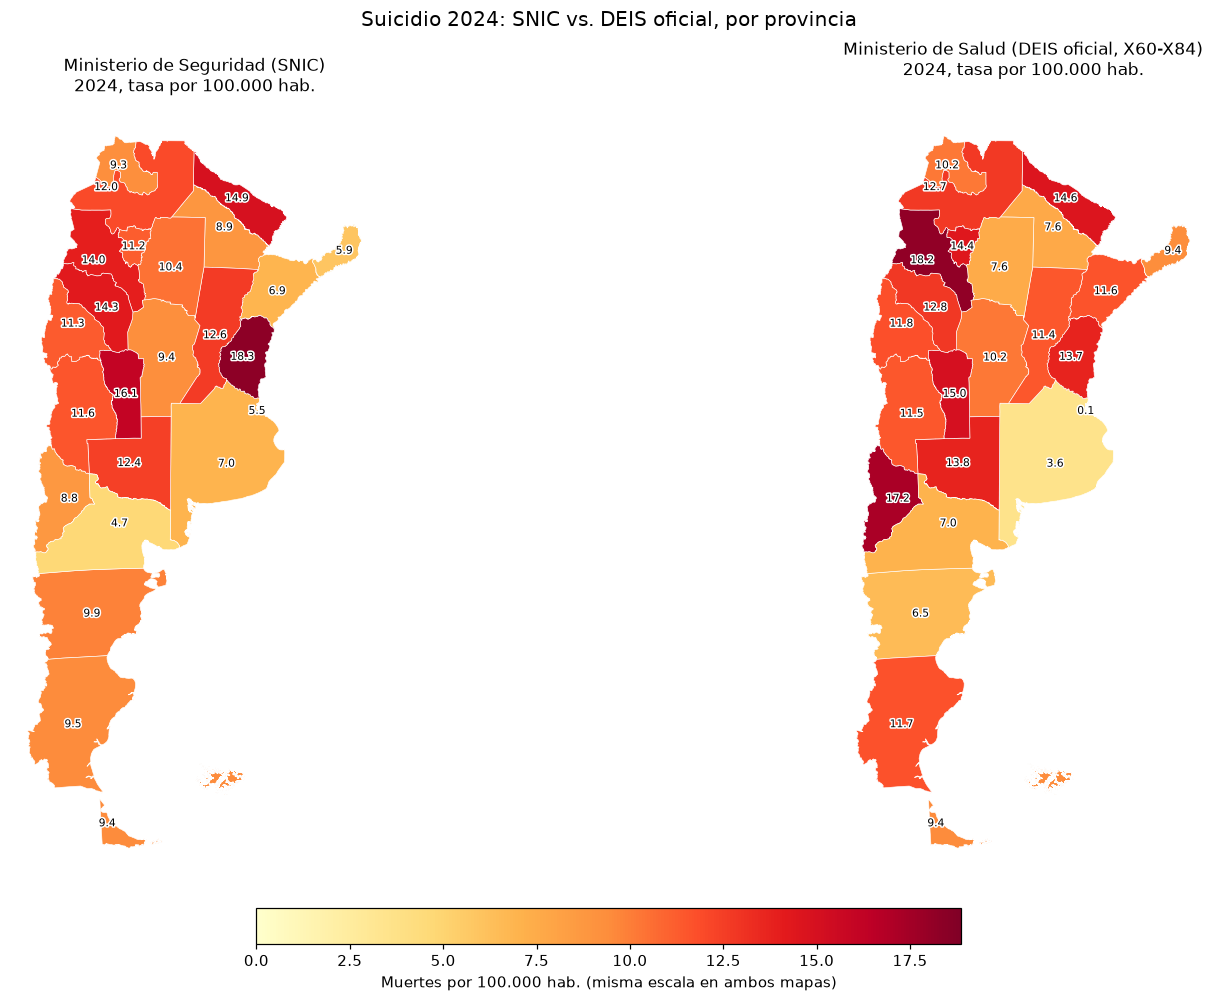

Correlación SNIC vs. DEIS oficial, 2024: r = 0.66


In [14]:
mapa_dos_paneles('SNIC', 'DEIS oficial',
                  'Ministerio de Seguridad (SNIC)', 'Ministerio de Salud (DEIS oficial, X60-X84)',
                  f'mapa_snic_vs_deis_oficial_{ANIO_MAPA}',
                  titulo_general=f'Suicidio {ANIO_MAPA}: SNIC vs. DEIS oficial, por provincia')

r = comp_2024[['SNIC', 'DEIS oficial']].corr().iloc[0, 1]
print(f'Correlación SNIC vs. DEIS oficial, {ANIO_MAPA}: r = {r:.2f}')


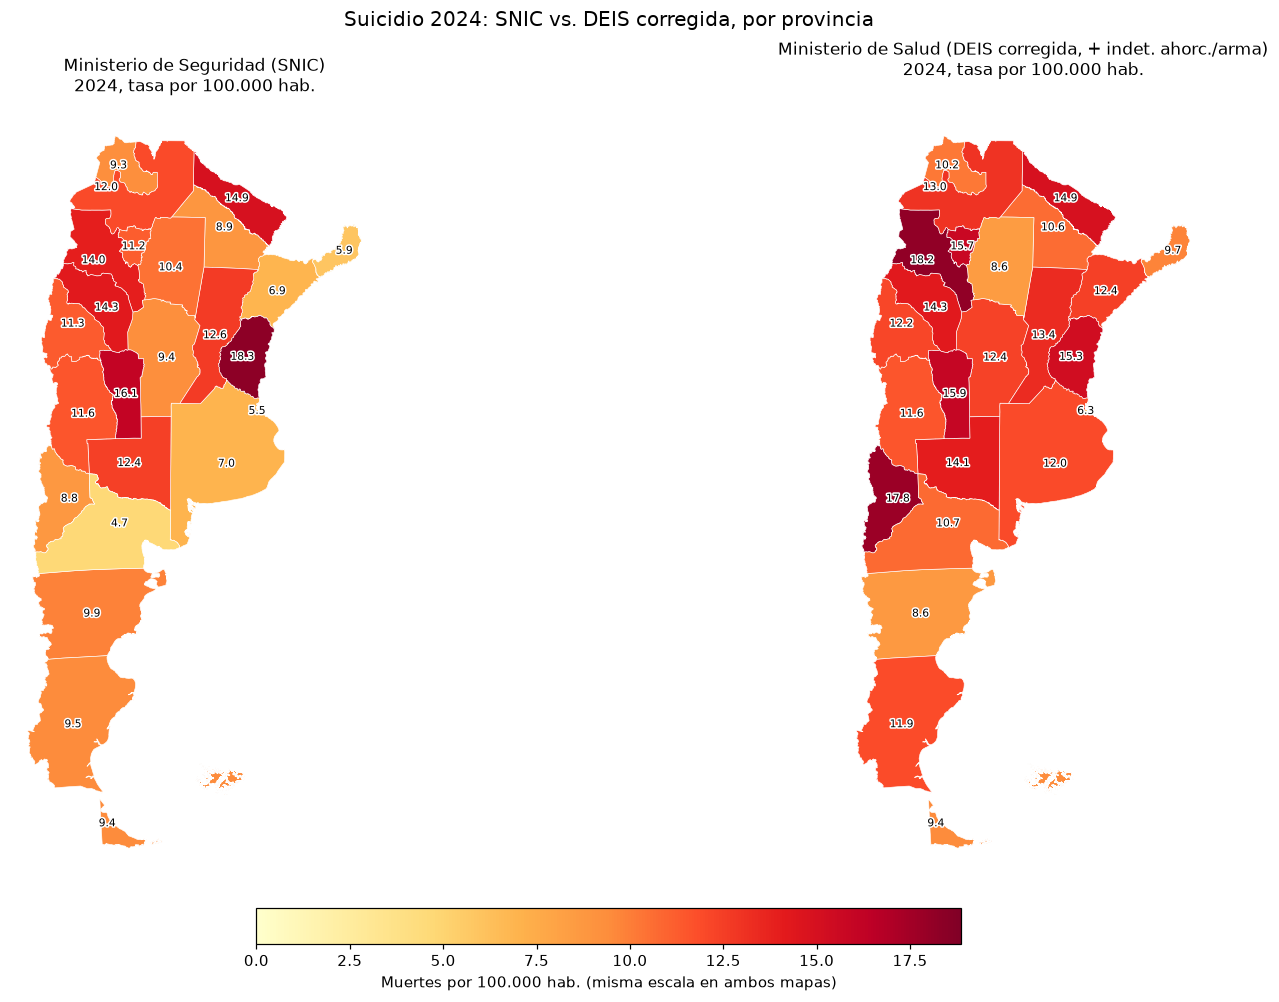

Correlación SNIC vs. DEIS corregida, 2024: r = 0.62


In [15]:
mapa_dos_paneles('SNIC', 'DEIS corregida',
                  'Ministerio de Seguridad (SNIC)', 'Ministerio de Salud (DEIS corregida, + indet. ahorc./arma)',
                  f'mapa_snic_vs_deis_corregida_{ANIO_MAPA}',
                  titulo_general=f'Suicidio {ANIO_MAPA}: SNIC vs. DEIS corregida, por provincia')

r = comp_2024[['SNIC', 'DEIS corregida']].corr().iloc[0, 1]
print(f'Correlación SNIC vs. DEIS corregida, {ANIO_MAPA}: r = {r:.2f}')


### 6.3 Líneas de tiempo

Tres vistas del mismo cruce en el tiempo: (a) nivel nacional, las tres series juntas; (b) la **brecha** SNIC vs. DEIS oficial a lo largo de los años — ¿se achica o se agranda?; (c) el mismo cruce, pero desagregado por provincia, para los cuatro casos más comentados hasta acá (CABA, Buenos Aires, Córdoba, Entre Ríos).


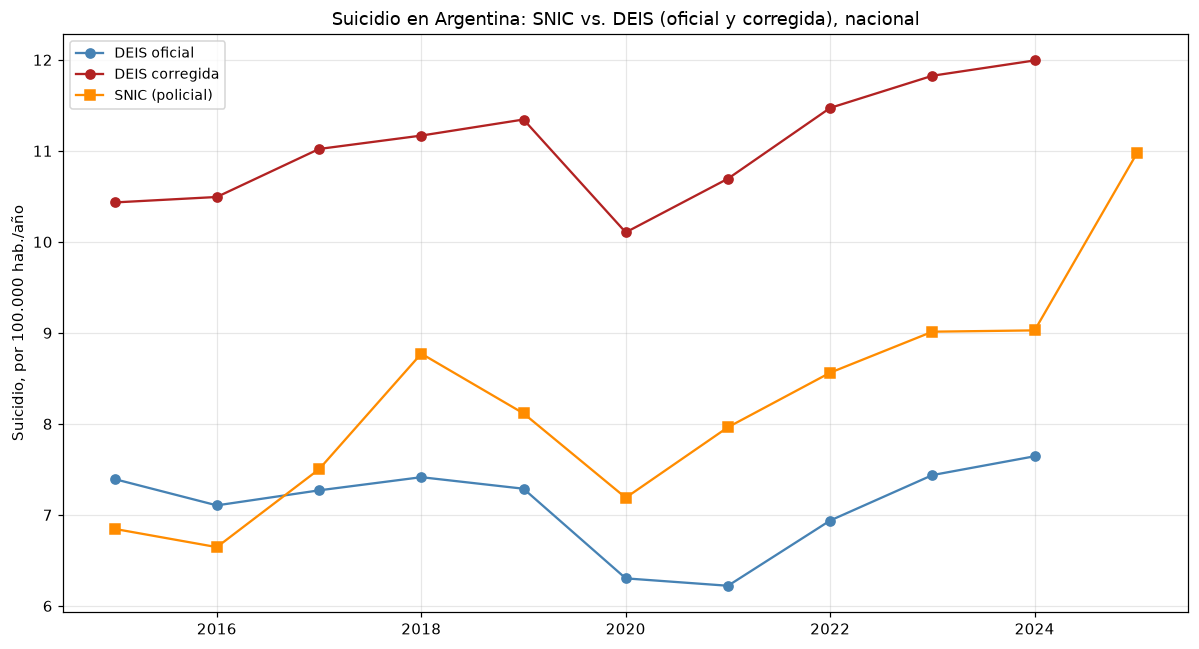

In [16]:
# --- (a) Nacional: SNIC, DEIS oficial, DEIS corregida ---
ANIO_DESDE = 2015  # antes de esto SNIC tiene el hueco de reporte de Buenos Aires (seccion 6.4)

pob_nac_year = pob_prov_year_full.groupby('anio').sum()

snic_nac = snic_prov_year_full.groupby('anio')[['victimas', 'poblacion']].sum()
snic_nac['SNIC'] = snic_nac['victimas'] / snic_nac['poblacion'] * 100_000
snic_nac = snic_nac[snic_nac.index >= ANIO_DESDE]

deis_nac = deis_prov_year.groupby('anio')[['DEIS oficial', 'DEIS corregida']].sum()
deis_nac = deis_nac.div(pob_nac_year, axis=0) * 100_000
deis_nac = deis_nac[deis_nac.index >= ANIO_DESDE]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(deis_nac.index, deis_nac['DEIS oficial'], marker='o', color='steelblue', label='DEIS oficial')
ax.plot(deis_nac.index, deis_nac['DEIS corregida'], marker='o', color='firebrick', label='DEIS corregida')
ax.plot(snic_nac.index, snic_nac['SNIC'], marker='s', color='darkorange', label='SNIC (policial)')
ax.set_ylabel('Suicidio, por 100.000 hab./año')
ax.set_title('Suicidio en Argentina: SNIC vs. DEIS (oficial y corregida), nacional')
ax.legend(fontsize=9)
plt.tight_layout(); guardar_fig('linea_tiempo_snic_vs_deis_nacional'); plt.show()


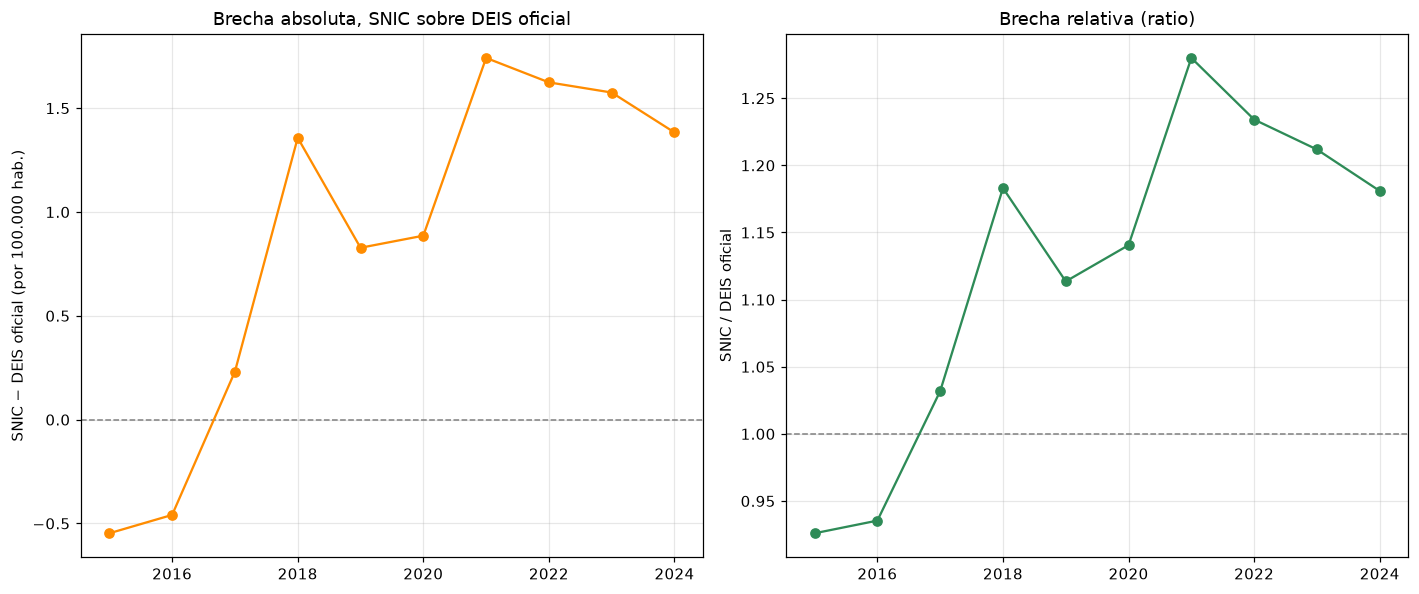

En 2015, SNIC era 0.93x DEIS oficial; en 2024, 1.18x.


In [17]:
# --- (b) Brecha SNIC - DEIS oficial, y SNIC / DEIS oficial, nacional ---
comun = deis_nac.dropna(how='all').join(snic_nac['SNIC'], how='inner').dropna()
comun['brecha_absoluta'] = comun['SNIC'] - comun['DEIS oficial']
comun['ratio'] = comun['SNIC'] / comun['DEIS oficial']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].axhline(0, color='gray', ls='--', lw=1)
axes[0].plot(comun.index, comun['brecha_absoluta'], marker='o', color='darkorange')
axes[0].set_ylabel('SNIC \u2212 DEIS oficial (por 100.000 hab.)')
axes[0].set_title('Brecha absoluta, SNIC sobre DEIS oficial')

axes[1].axhline(1, color='gray', ls='--', lw=1)
axes[1].plot(comun.index, comun['ratio'], marker='o', color='seagreen')
axes[1].set_ylabel('SNIC / DEIS oficial')
axes[1].set_title('Brecha relativa (ratio)')

plt.tight_layout(); guardar_fig('brecha_snic_deis_oficial_nacional'); plt.show()
print(f"En {comun.index.min()}, SNIC era {comun['ratio'].iloc[0]:.2f}x DEIS oficial; "
      f"en {comun.index.max()}, {comun['ratio'].iloc[-1]:.2f}x.")


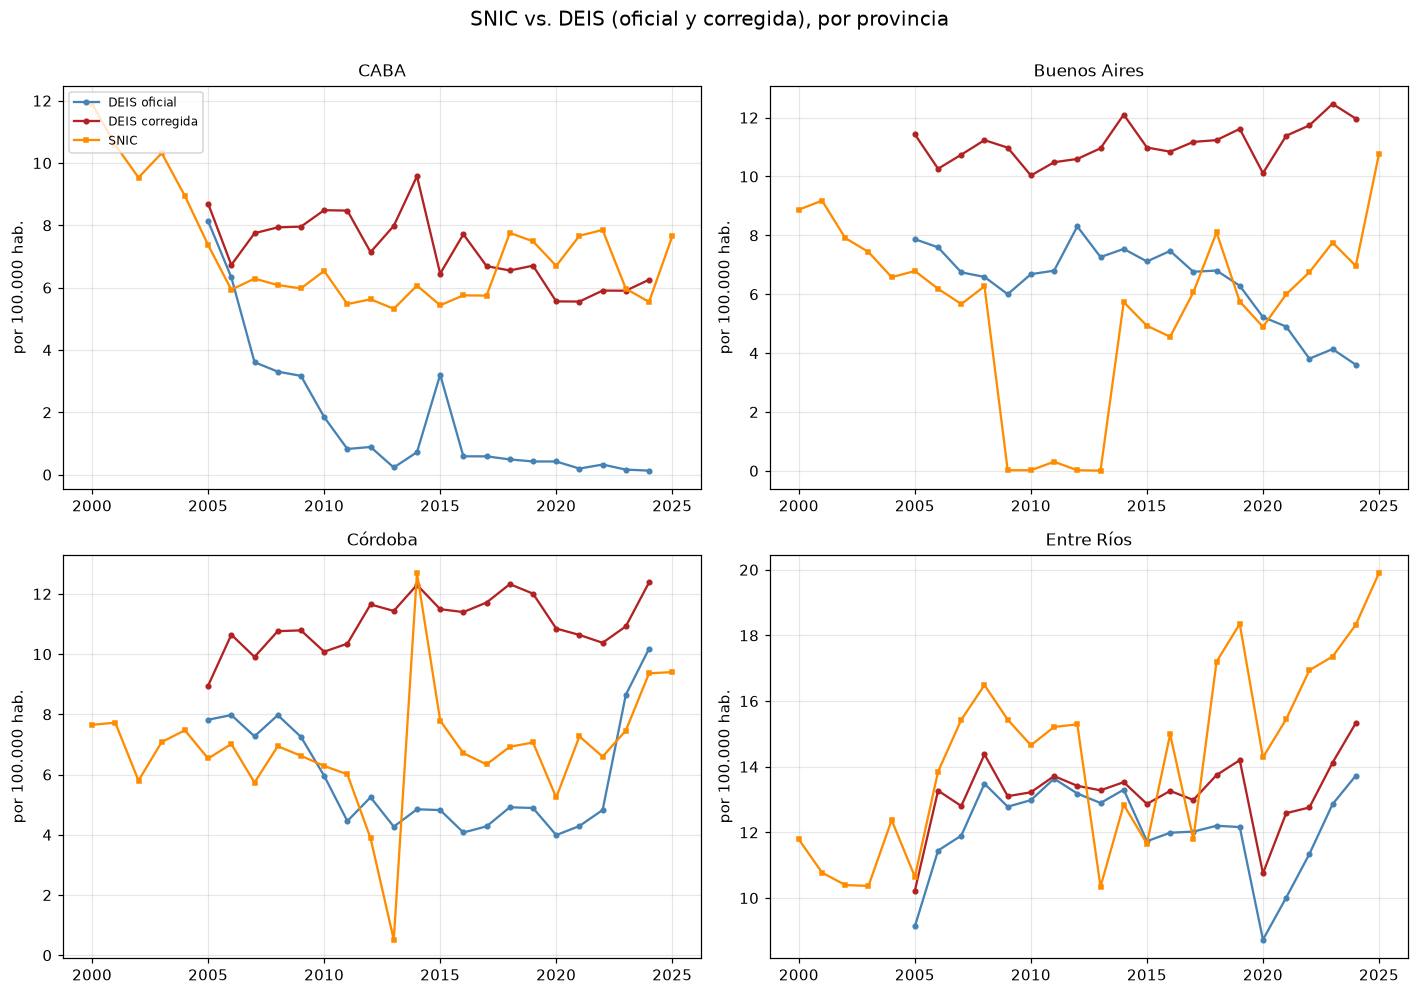

In [18]:
# --- (c) Por provincia: CABA, Buenos Aires, Cordoba, Entre Rios ---
PROVS_DESTACADAS = ['caba', 'buenos aires', 'cordoba', 'entre rios']

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=False)
for ax, pk in zip(axes.flat, PROVS_DESTACADAS):
    d = deis_tasa_prov.xs(pk, level='prov_key')
    s = snic_prov_year_full.xs(pk, level='prov_key')
    ax.plot(d.index, d['DEIS oficial'], marker='o', ms=3, color='steelblue', label='DEIS oficial')
    ax.plot(d.index, d['DEIS corregida'], marker='o', ms=3, color='firebrick', label='DEIS corregida')
    ax.plot(s.index, s['tasa'], marker='s', ms=3, color='darkorange', label='SNIC')
    ax.set_title(nombre_prov.loc[pk, 'provincia_nombre'], fontsize=11)
    ax.set_ylabel('por 100.000 hab.')

axes[0, 0].legend(fontsize=8, loc='upper left')
fig.suptitle('SNIC vs. DEIS (oficial y corregida), por provincia', fontsize=13, y=1.0)
plt.tight_layout(); guardar_fig('linea_tiempo_snic_vs_deis_por_provincia'); plt.show()


**Lectura:** en el panel (b), un ratio SNIC/DEIS oficial establemente > 1 a lo largo de toda la serie sería la señal más fuerte de subregistro sistemático (no un artefacto de un año puntual); si el ratio viene bajando, podría leerse como mejora en la calidad de certificación de DEIS con el tiempo — chequear el signo y la magnitud reales antes de asumir cualquiera de las dos lecturas. En (c), comparar la forma de las curvas (no solo el nivel): si DEIS oficial y SNIC se mueven en paralelo pero con un nivel distinto, es un sesgo de nivel (más fácil de "corregir"); si divergen en el tiempo, es un problema más difícil de resolver con un factor fijo.


### 6.4 Ojo: corte de reporte de SNIC en Buenos Aires, 2009-2013

El panel de Buenos Aires en 6.3(c) tiene un pozo que no es una caída real de suicidios: es un **corte de reporte** en la fuente SNIC. `cantidad_victimas` de Buenos Aires cae de ~1.000/año a **3, 3, 49, 3 y 1** en 2009-2013, y vuelve de un salto a ~900+ en 2014 (ver abajo). Como Buenos Aires es ~40% de la población del país, ese hueco es el que explica el pozo nacional de 2009-2013 en el gráfico (a) — no es que haya bajado el suicidio en Argentina esos años, es que la provincia más grande dejó de reportarle datos completos a SNIC. Córdoba tiene un pico de un solo año con el mismo perfil sospechoso. **Para cualquier lectura de la serie 2009-2013, usar DEIS (que no tiene este problema) en vez de SNIC.**


In [19]:
bsas_snic = suic_prov[suic_prov['prov_key'] == 'buenos aires'][['anio', 'cantidad_hechos', 'cantidad_victimas']]
print('SNIC, Buenos Aires, "Suicidios (consumados)" por año (nótese 2009-2013):')
display(bsas_snic.sort_values('anio').set_index('anio').loc[2005:2016])


SNIC, Buenos Aires, "Suicidios (consumados)" por año (nótese 2009-2013):


,cantidad_hechos,cantidad_victimas
anio,,
2005,1010,1010.0
2006,931,931.0
2007,863,863.0
2008,966,966.0
2009,0,3.0
2010,0,3.0
2011,49,49.0
2012,3,3.0
2013,1,1.0


### 6.5 Áreas más afectadas por provincia: SNIC vs. DEIS

Mismo ejercicio de la sección 3 (SNIC, acumulado multi-año para evitar ruido de un año suelto), pero ahora sumando las dos versiones de DEIS al lado para ver si las tres fuentes coinciden en qué provincias están peor. Ventana: SNIC 2015-2025 (la misma que ya se mostró en 3), DEIS 2015-2024 (último año disponible) — no son exactamente el mismo rango de años, así que compará el **orden** entre columnas, no el valor exacto entre SNIC y DEIS fila a fila.


In [20]:
ANIOS_DEIS_RANK = list(range(2015, 2025))  # DEIS: hasta 2024 (no hay 2025 todavia)

deis_acum = (deis_prov_year.loc[(slice(None), ANIOS_DEIS_RANK), ['DEIS oficial', 'DEIS corregida']]
             .groupby(level='prov_key').sum())
pob_acum_deis = pob_prov_year_full.loc[(slice(None), ANIOS_DEIS_RANK)].groupby(level='prov_key').sum()
deis_rank_prov = deis_acum.div(pob_acum_deis, axis=0) * 100_000

rank_cmp = (rank_prov[['tasa']].rename(columns={'tasa': 'SNIC (2015-2025)'})
            .join(deis_rank_prov.rename(columns={'DEIS oficial': 'DEIS oficial (2015-2024)',
                                                   'DEIS corregida': 'DEIS corregida (2015-2024)'}))
            .join(nombre_prov)
            .sort_values('SNIC (2015-2025)', ascending=False))

print('Tasa de suicidio por provincia, SNIC vs. DEIS (promedio anual, por 100.000 hab.):')
display(rank_cmp[['provincia_nombre', 'SNIC (2015-2025)', 'DEIS oficial (2015-2024)',
                   'DEIS corregida (2015-2024)']].round(2))


Tasa de suicidio por provincia, SNIC vs. DEIS (promedio anual, por 100.000 hab.):


,provincia_nombre,SNIC (2015-2025),DEIS oficial (2015-2024),DEIS corregida (2015-2024)
prov_key,,,,
entre rios,Entre Ríos,16.08,11.68,13.27
salta,Salta,13.06,13.05,13.40
san luis,San Luis,12.06,8.65,11.94
catamarca,Catamarca,11.30,14.49,14.66
santiago del estero,Santiago del Estero,11.24,8.71,9.58
santa cruz,Santa Cruz,10.66,10.27,12.57
la rioja,La Rioja,10.61,10.62,11.85
santa fe,Santa Fe,10.60,7.63,12.16
formosa,Formosa,10.38,9.70,10.20


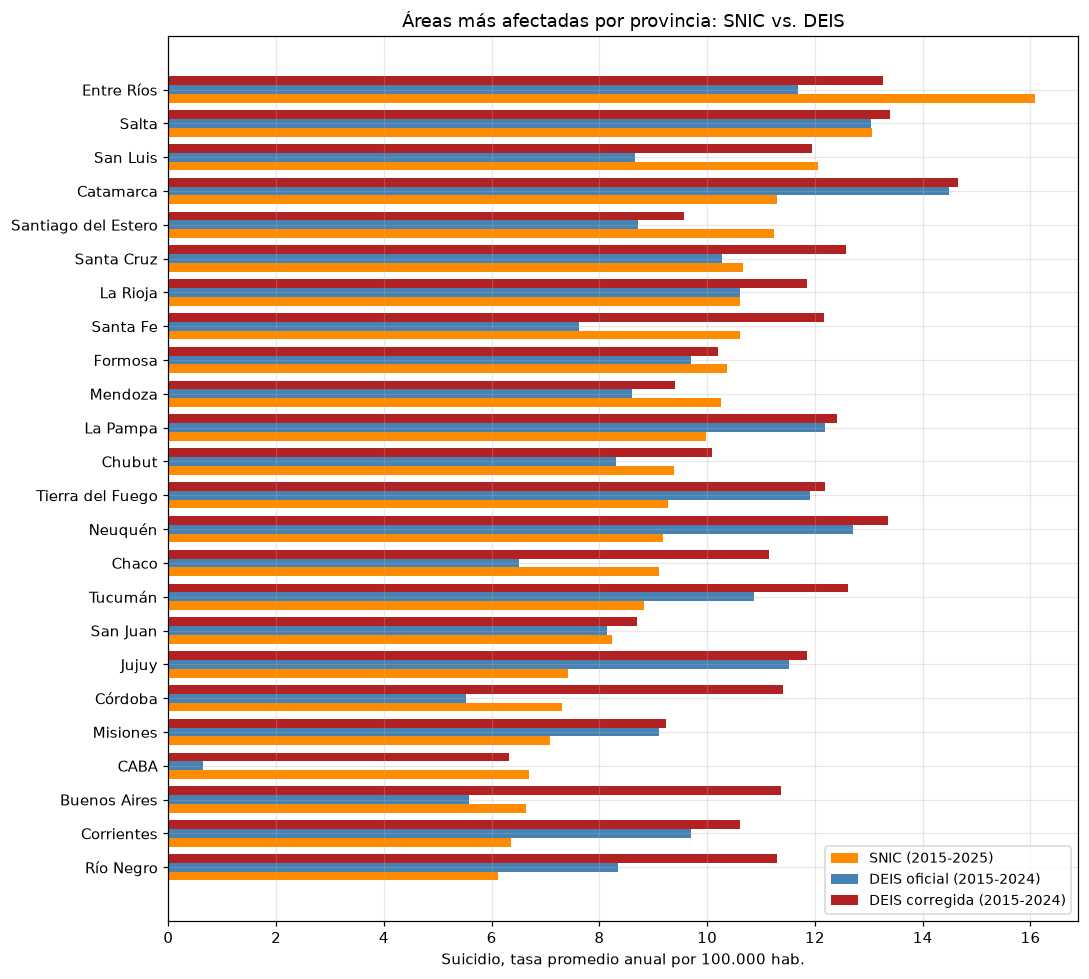

In [21]:
fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(rank_cmp))
alto = 0.26

orden = rank_cmp.iloc[::-1]
ax.barh(y - alto, orden['SNIC (2015-2025)'], alto, color='darkorange', label='SNIC (2015-2025)')
ax.barh(y, orden['DEIS oficial (2015-2024)'], alto, color='steelblue', label='DEIS oficial (2015-2024)')
ax.barh(y + alto, orden['DEIS corregida (2015-2024)'], alto, color='firebrick', label='DEIS corregida (2015-2024)')

ax.set_yticks(y); ax.set_yticklabels(orden['provincia_nombre'])
ax.set_xlabel('Suicidio, tasa promedio anual por 100.000 hab.')
ax.set_title('\u00c1reas m\u00e1s afectadas por provincia: SNIC vs. DEIS')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout(); guardar_fig('areas_mas_afectadas_por_provincia_snic_vs_deis'); plt.show()


**Lectura:** ninguna provincia encabeza las tres columnas a la vez. Entre Ríos lidera en SNIC (16.1) pero queda 4ta en DEIS oficial (11.7) y en DEIS corregida (13.3); Catamarca es la que domina en las dos versiones de DEIS (14.5 oficial, 14.7 corregida) pero cae al 4to lugar en SNIC (11.3). Para el resto, comparar el **orden relativo** entre columnas: una provincia que sube mucho de posición en DEIS corregida respecto a DEIS oficial (típicamente CABA, Buenos Aires, Córdoba) es la misma señal de la sección 12.7/14 del otro notebook — ahora con SNIC como tercer punto de referencia para juzgar cuál de las dos versiones de DEIS queda más cerca de una fuente no sanitaria.
